# Solving the Traveling Salesman  Problem using Local Search

Points: 10

## The [Traveling Salesman Problem](https://en.wikipedia.org/wiki/Travelling_salesman_problem)

* __Goal:__ Find the shortest tour visiting each of $n$ cities exactly once and returning back to the starting city. Given are pairwise distances between cities, where $d_{i,j}$ is the distance from city $i$ to city $j$. 

* __State space:__ Each state represents a tour. The cities are numbered and a tour can be expressed as vector  $\pi$ with the order in which the cities are visited (a [permutation](https://en.wikipedia.org/wiki/Permutation)). That is, $\pi(1)$ is the index of the first city to visit, $\pi(2)$ the index of the second, and so on.

* __Objective function:__ Minimize the tour length. The optimization problem is to find the optimal tour $\pi^*$ through the $n$ cities and returning to the starting city:

  > minimize: $\mathrm{tourlength}(\pi) = d_{\pi(n),\pi(1)} + \sum_{i = 1}^{n-1} d_{\pi(i),\pi(i+1)}$
  > 
  > subject to: $\pi \ \text{is a valid permutation vector}$

* __Local moves:__ Exchange two cities in the order.

## Helper functions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import random

# Fixed seeds for reproducible experiments.
random.seed(1234)
np.random.seed(1234)
np.set_printoptions(precision=2)
pd.set_option('display.precision', 2)


/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-0o7bek4h because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [2]:
def random_tour(n):
    """Create a random tour"""
    
    tour = list(range(n))
    random.shuffle(tour)
    return(tour)

random_tour(10)

[2, 8, 3, 5, 6, 4, 9, 0, 1, 7]

In [3]:
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

def random_tsp(n):
    """
    Create a random (Euclidean) traveling salesman problem. Choose n points randomly in a 1 x 1 unit square and calulates a 
    pairwise Euclidean distance matrix.
    """
    
    pos = pd.DataFrame({
        "x" : np.random.uniform(size = n),
        "y" : np.random.uniform(size = n)
    })
    
    dist = squareform(pdist(pos))
    
    return({"pos": pos, "dist": dist})
    
tsp = random_tsp(10)

print(f"Positions:\n{tsp['pos']}")
print(f"Distance matrix:\n{pd.DataFrame(tsp['dist'])})")

Positions:
      x     y
0  0.19  0.36
1  0.62  0.50
2  0.44  0.68
3  0.79  0.71
4  0.78  0.37
5  0.27  0.56
6  0.28  0.50
7  0.80  0.01
8  0.96  0.77
9  0.88  0.88
Distance matrix:
      0     1     2     3     4     5     6     7     8     9
0  0.00  0.45  0.41  0.69  0.59  0.22  0.17  0.70  0.87  0.86
1  0.45  0.00  0.26  0.27  0.20  0.35  0.35  0.52  0.43  0.46
2  0.41  0.26  0.00  0.35  0.46  0.21  0.24  0.76  0.53  0.48
3  0.69  0.27  0.35  0.00  0.34  0.53  0.55  0.70  0.18  0.19
4  0.59  0.20  0.46  0.34  0.00  0.54  0.52  0.36  0.44  0.52
5  0.22  0.35  0.21  0.53  0.54  0.00  0.06  0.76  0.72  0.68
6  0.17  0.35  0.24  0.55  0.52  0.06  0.00  0.72  0.73  0.71
7  0.70  0.52  0.76  0.70  0.36  0.76  0.72  0.00  0.77  0.87
8  0.87  0.43  0.53  0.18  0.44  0.72  0.73  0.77  0.00  0.14
9  0.86  0.46  0.48  0.19  0.52  0.68  0.71  0.87  0.14  0.00)


In [4]:
def tour_length(tsp, tour):
    """Caclulate the length of a tour, i.e., the objective function."""
    
    # make sure tour is a Python list (not an array or a numpy.array)
    if not isinstance(tour, list): tour = tour.tolist()
    
    tl = 0
    dist = tsp["dist"]
    
    for i in range(len(tour)-1):
        tl += dist[tour[i], tour[i+1]]
    
    tl += dist[tour[-1], tour[0]]
    
    return(tl)
        
tour = random_tour(10)
tour_length(tsp, tour)

np.float64(5.873881857725191)

Tour length: 5.87


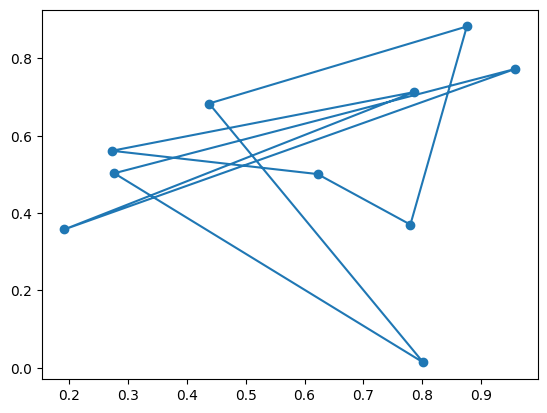

In [5]:
def show_tsp(tsp, tour = None):  
    """display the traveling salesman problem and a tour."""
    
    pos = tsp["pos"]
    
    plt.scatter(pos["x"], pos["y"])
    
    if tour is not None:
        # make sure tour is a Python list (not an array or a numpy.array)
        if not isinstance(tour, list): tour = tour.tolist()
        
        print(f"Tour length: {round(tour_length(tsp, tour), 2)}")
        
        pos_ = pos.reindex(tour)
        pos_ = pd.concat([pos_, pos_.head(1)])
        plt.plot(pos_["x"], pos_["y"])
    
    plt.show()
    
show_tsp(tsp, tour)

## Steepest-ascend Hill Climbing Search [3 Points]

Calculate the objective function for all local moves (move each queen within its column) and always choose the best among all local moves.

Best tour length: 2.8056 evaluations: 226
Tour length: 2.81


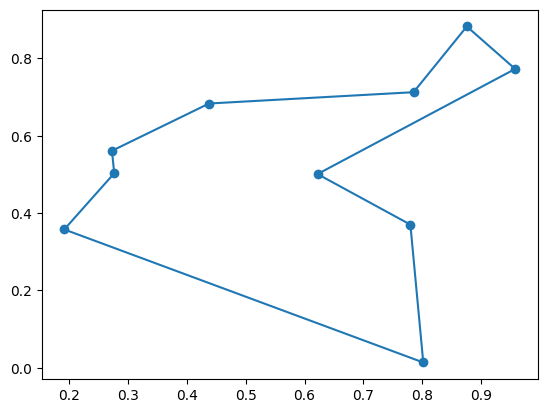

In [6]:
def neighbors_swap(tour):
    """All tours formed by swapping two distinct city positions."""
    out=[]
    for i in range(len(tour)-1):
        for j in range(i+1,len(tour)):
            candidate=tour.copy(); candidate[i],candidate[j]=candidate[j],candidate[i]; out.append(candidate)
    return out

def steepest_hill_climbing_tsp(tsp, tour=None, max_steps=1000):
    if tour is None: tour=random_tour(len(tsp['pos']))
    tour=tour.copy(); history=[tour_length(tsp,tour)]; evaluations=1
    for _ in range(max_steps):
        current=history[-1]; best_tour=tour; best=current
        for candidate in neighbors_swap(tour):
            value=tour_length(tsp,candidate); evaluations+=1
            if value < best: best_tour,best=candidate,value
        if best >= current: break
        tour=best_tour; history.append(best)
    return {'tour':tour,'length':tour_length(tsp,tour),'history':history,'evaluations':evaluations}

result=steepest_hill_climbing_tsp(tsp)
print('Best tour length:',round(result['length'],4),'evaluations:',result['evaluations'])
show_tsp(tsp,result['tour'])


## Steepest-ascend Hill Climbing Search with Random Restarts [1 Point]

Steepest-ascend with random restarts.

Random restart best length: 2.7636 restarts: 50
Tour length: 2.76


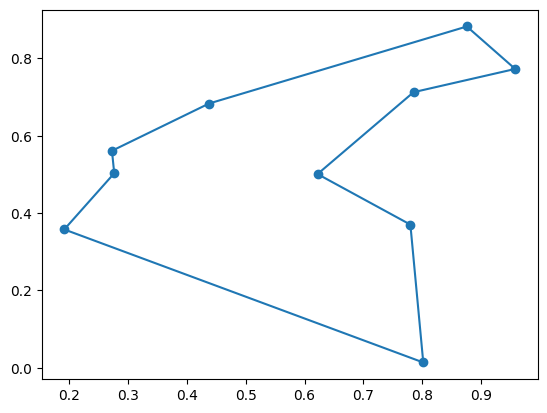

In [7]:
def random_restart_tsp(tsp, restarts=50):
    best=None
    for _ in range(restarts):
        result=steepest_hill_climbing_tsp(tsp,random_tour(len(tsp['pos'])))
        if best is None or result['length']<best['length']: best=result
    best['restarts']=restarts
    return best

rr_result=random_restart_tsp(tsp, restarts=50)
print('Random restart best length:',round(rr_result['length'],4),'restarts:',rr_result['restarts'])
show_tsp(tsp,rr_result['tour'])


## Stochastic Hill Climbing [1 Points]

Chooses randomly from among all uphill moves.

In [8]:
def stochastic_hill_climbing_tsp(tsp, tour=None, max_steps=1000):
    if tour is None: tour=random_tour(len(tsp['pos']))
    tour=tour.copy(); history=[tour_length(tsp,tour)]; evaluations=1
    for _ in range(max_steps):
        current=history[-1]
        candidates=[]
        for candidate in neighbors_swap(tour):
            value=tour_length(tsp,candidate); evaluations+=1
            if value < current: candidates.append((candidate,value))
        if not candidates: break
        tour,value=random.choice(candidates); history.append(value)
    return {'tour':tour,'length':tour_length(tsp,tour),'history':history,'evaluations':evaluations}

stoch_result=stochastic_hill_climbing_tsp(tsp)
print('Stochastic best length:',round(stoch_result['length'],4),'evaluations:',stoch_result['evaluations'])


Stochastic best length: 2.8056 evaluations: 541


## First-choice Hill Climbing [1 Point]

First-choice hill climbing is a type of stochastic hill climbing that generates one random local neighbor at a time and accept it if it has a better objective function value than the current state.

In [9]:
def first_choice_hill_climbing_tsp(tsp, tour=None, max_trials_without_improvement=2000, max_steps=1000):
    if tour is None: tour=random_tour(len(tsp['pos']))
    tour=tour.copy(); current=tour_length(tsp,tour); history=[current]; evaluations=1; failed=0
    n=len(tour)
    for _ in range(max_steps):
        if failed>=max_trials_without_improvement: break
        i,j=random.sample(range(n),2); candidate=tour.copy(); candidate[i],candidate[j]=candidate[j],candidate[i]
        value=tour_length(tsp,candidate); evaluations+=1
        if value<current:
            tour=candidate; current=value; history.append(value); failed=0
        else: failed+=1
    return {'tour':tour,'length':current,'history':history,'evaluations':evaluations}

fc_result=first_choice_hill_climbing_tsp(tsp)
print('First-choice best length:',round(fc_result['length'],4),'evaluations:',fc_result['evaluations'])


First-choice best length: 2.8811 evaluations: 1001


## Simulated Annealing [2 Points]

Simulated annealing best length: 2.8811 evaluations: 5001
Tour length: 2.88


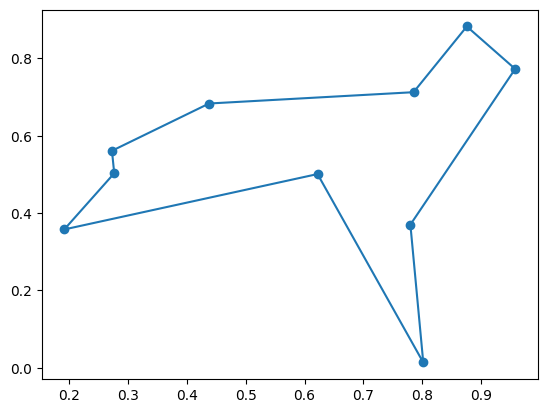

In [10]:
def simulated_annealing_tsp(tsp, tour=None, T0=0.1, alpha=0.995, max_steps=5000):
    if tour is None: tour=random_tour(len(tsp['pos']))
    tour=tour.copy(); current=tour_length(tsp,tour); best_tour=tour.copy(); best=current
    history=[current]; evaluations=1
    for t in range(1,max_steps+1):
        n=len(tour); i,j=random.sample(range(n),2); candidate=tour.copy(); candidate[i],candidate[j]=candidate[j],candidate[i]
        value=tour_length(tsp,candidate); evaluations+=1; T=max(1e-12,T0*(alpha**t)); delta=value-current
        if delta<0 or random.random()<math.exp(-delta/T): tour=candidate; current=value
        if current<best: best=current; best_tour=tour.copy()
        history.append(current)
    return {'tour':best_tour,'length':best,'history':history,'evaluations':evaluations}

sa_result=simulated_annealing_tsp(tsp)
print('Simulated annealing best length:',round(sa_result['length'],4),'evaluations:',sa_result['evaluations'])
show_tsp(tsp,sa_result['tour'])


## Compare Performance [2 Points]

Use runtime, scalability (number of cities), and best objective function value to compare the algorithms on boards of different sizes.  

For timing you can use the `time` package.

In [11]:
import time

t0 = time.time()
print("Do something")
t1 = time.time()

print(f"This took: {(t1-t0) * 1e3} milliseconds")

Do something
This took: 0.08535385131835938 milliseconds


,Cities,Algorithm,Mean tour length,Best tour length,Mean runtime (ms),Repetitions
0,8,Steepest HC,2.70,2.70,0.21,20
1,8,Random restart,2.70,2.70,4.20,20
2,8,Stochastic HC,2.70,2.70,0.32,20
3,8,First-choice HC,2.70,2.70,2.87,20
4,8,Simulated annealing,2.70,2.70,6.79,20
5,12,Steepest HC,3.41,3.23,1.23,20
6,12,Random restart,3.23,3.23,21.85,20
7,12,Stochastic HC,3.69,3.23,1.92,20
8,12,First-choice HC,3.61,3.23,3.42,20
9,12,Simulated annealing,3.41,3.23,6.84,20


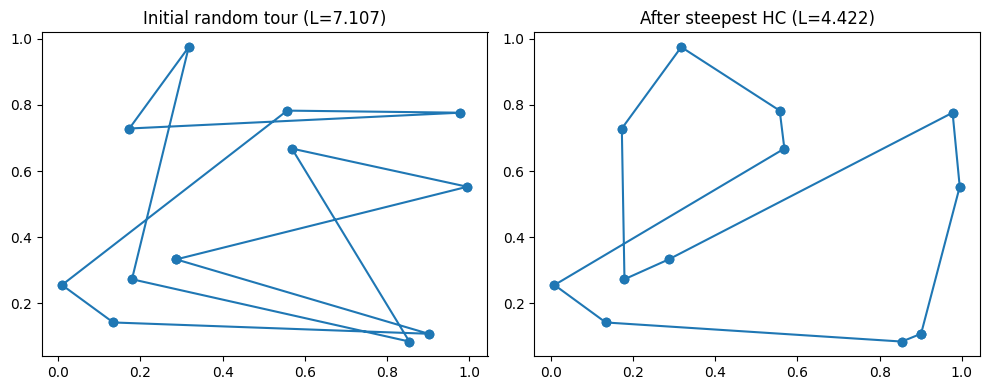

In [12]:
# Repeated comparison on the same city set for each n.
# Every method is repeated 20 times because its initial tour and/or search path is random.
import time
comparison_rows=[]
repetitions=20
for n in (8,12,16,20):
    problem=random_tsp(n)
    methods={
        'Steepest HC':lambda:steepest_hill_climbing_tsp(problem),
        'Random restart':lambda:random_restart_tsp(problem,restarts=20),
        'Stochastic HC':lambda:stochastic_hill_climbing_tsp(problem),
        'First-choice HC':lambda:first_choice_hill_climbing_tsp(problem),
        'Simulated annealing':lambda:simulated_annealing_tsp(problem,max_steps=2000),
    }
    for name,fn in methods.items():
        lengths=[]; durations=[]
        for _ in range(repetitions):
            t0=time.perf_counter(); out=fn(); durations.append((time.perf_counter()-t0)*1000)
            lengths.append(out['length'])
        comparison_rows.append({
            'Cities':n, 'Algorithm':name,
            'Mean tour length':float(np.mean(lengths)),
            'Best tour length':float(np.min(lengths)),
            'Mean runtime (ms)':float(np.mean(durations)),
            'Repetitions':repetitions
        })
comparison_df=pd.DataFrame(comparison_rows)
display(comparison_df.round(4))
# Illustration: initial random tour vs optimized tour on a separate 12-city problem.
problem=random_tsp(12); initial=random_tour(12); optimized=steepest_hill_climbing_tsp(problem,initial)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,route,title in [(axes[0],initial,'Initial random tour'),(axes[1],optimized['tour'],'After steepest HC')]:
    pos=problem['pos']; ordered=pos.reindex(route); ordered=pd.concat([ordered,ordered.head(1)])
    ax.scatter(pos.x,pos.y); ax.plot(ordered.x,ordered.y,'-o'); ax.set_title(f'{title} (L={tour_length(problem,route):.3f})')
plt.tight_layout(); plt.show()


## Bonus: Genetic Algorithm [+1 Point]

In [13]:
# Optional bonus: Genetic Algorithm. This is outside the required core deliverables and is not used in the report.